# Baku Microfinance — Credit Risk Scorecard
**Daily Data Analytics Project · Day 11**

## Business question
*A Baku microfinance lender approves consumer loans (AZN 300–30,000, 6–36 months) through branches, an online app and partner stores, using one affordability rule: instalments ≤ 80% of income. About one loan in nine goes 60+ days past due. **Can an application scorecard rank risk well enough to set an approval cut-off that raises portfolio profit, and is the scorecard still valid for today's applicants?***

Approach:
1. Clean 21 months of booked loans (Jan 2024 – Sep 2025), each with a 12-month outcome: **bad = 60+ days past due within 12 months on book**.
2. KPIs and EDA: bad rate by segment, vintage default curves.
3. **Weight-of-Evidence (WoE) binning** with monotonic bad-rate constraints and **Information Value (IV)** screening, written in pandas/NumPy.
4. **Logistic regression on WoE** → points-based scorecard (600 points = 50:1 good:bad odds, 20 points to double the odds).
5. Validation: Gini & KS on train, random test and **out-of-time** (Apr–Sep 2025), calibration, benchmark against the bureau score alone.
6. **Cut-off strategy:** profit per loan from simple unit economics, approval rate vs bad rate trade-off.
7. **Stability:** PSI/CSI of the 2026 through-the-door applications against the development sample.

> Data is **synthetic** (fixed seed), generated by `data/generate_data.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve
import scorecard as sc
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#898781", "axes.titleweight": "bold"})
BLUE, ORANGE, AQUA, YELLOW, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781", "#d03b3b"
pd.set_option("display.float_format", "{:,.3f}".format)
loans_raw, recent_raw = sc.load_raw()
print(loans_raw.shape, recent_raw.shape); loans_raw.head()

(24045, 18) (6000, 16)


,loan_id,application_date,channel,region,age,employment_type,employment_years,monthly_income_azn,salary_card_client,loan_purpose,loan_amount_azn,term_months,existing_loans,delinquencies_12m,bureau_score,debt_to_income,bad_60dpd_12m,months_to_default
0,LN100000,2024-01-02,online,Other regions,39,salaried_private,5.600,740.000,1,cash,"1,190.000",12,0,0,611.000,0.152,0,NaN
1,LN100001,2024-01-02,branch,Baku,29,informal,2.100,"1,140.000",0,home_repair,"2,270.000",12,0,0,537.000,0.188,0,NaN
2,LN100002,2024-01-02,branch,Baku,64,pensioner,0.000,500.000,0,home_repair,"3,930.000",12,0,2,474.000,0.743,1,8.000
3,LN100003,2024-01-02,partner_store,Baku,28,salaried_public,2.800,"1,720.000",0,consumer_goods,"2,330.000",6,1,0,605.000,0.349,0,NaN
4,LN100004,2024-01-02,branch,Baku,49,salaried_private,7.000,"1,440.000",0,cash,"3,810.000",24,1,0,616.000,0.186,0,NaN


## 1. Data quality check

In [2]:
df, log = sc.clean(loans_raw)
recent, rlog = sc.clean(recent_raw)
T = sc.TARGET
checks = {**log,
 "Date range": f"{df.application_date.min():%Y-%m-%d} → {df.application_date.max():%Y-%m-%d}",
 "Duplicate loan_id after cleaning": int(df.loan_id.duplicated().sum()),
 "Target values": str(sorted(df[T].unique())),
 "Bads without months_to_default / goods with it": f"{int((df[T].eq(1) & df.months_to_default.isna()).sum())} / {int((df[T].eq(0) & df.months_to_default.notna()).sum())}",
 "Loan amount outside AZN 300–30,000": int((~df.loan_amount_azn.between(300, 30000)).sum()),
 "Term not in {6,12,18,24,36}": int((~df.term_months.isin([6, 12, 18, 24, 36])).sum()),
 "Debt-to-income > 0.8 (policy exceptions)": int((df.debt_to_income > 0.8).sum()),
 "Recent applications (2026) rows / issues fixed": f"{len(recent):,} / {sum(v for k, v in rlog.items() if k not in ('Rows in', 'Rows out', 'Missing bureau score = thin file (own bin)'))}",
}
pd.Series(checks).to_frame("result")

,result
Rows in,24045
Exact duplicate rows dropped,45
Incomes keyed in qəpik (÷100),20
Impossible ages set to missing,6
Employment years > adult life set to missing,24
Missing income (kept as own WoE bin),150
Missing bureau score = thin file (own bin),3241
Rows out,24000
Date range,2024-01-02 → 2025-09-30
Duplicate loan_id after cleaning,0


Fixes: 45 exact duplicate rows dropped; 20 incomes keyed in *qəpik* divided by 100; 6 impossible ages (0, 7, 199, 230) and 24 employment tenures longer than the applicant's adult life set to missing. Missing values are **not imputed**: in a WoE scorecard, "missing" becomes its own bin with its own risk. That matters most for the **13.5% of applicants with no credit-bureau record** (thin file). They are a real segment, not a data error. The 400-odd loans with debt-to-income above 0.8 are small loans where the AZN 300 minimum already breaks the rule. They are kept, because they really were booked.

## 2. Headline KPIs

In [3]:
df["quarter"] = df.application_date.dt.to_period("Q").astype(str)
df["loss_azn"] = np.where(df[T] == 1, df.loan_amount_azn * 0.8 * 0.7, 0)
K = {
 "Booked loans": f"{len(df):,}",
 "Disbursed volume, AZN": f"{df.loan_amount_azn.sum():,.0f}",
 "Average loan / median term": f"AZN {df.loan_amount_azn.mean():,.0f} / {df.term_months.median():.0f} months",
 "Bad rate (60+ DPD in 12m), by count": f"{df[T].mean():.2%}",
 "Bad rate by volume (AZN)": f"{np.average(df[T], weights=df.loan_amount_azn):.2%}",
 "Estimated credit loss, AZN (EAD 80% × LGD 70%)": f"{df.loss_azn.sum():,.0f}",
 "Bad rate: Jan 2024–Mar 2025 vs Apr–Sep 2025": f"{df.loc[df.application_date < '2025-04-01', T].mean():.2%} vs {df.loc[df.application_date >= '2025-04-01', T].mean():.2%}",
 "Thin-file share / their bad rate": f"{df.bureau_score.isna().mean():.1%} / {df.loc[df.bureau_score.isna(), T].mean():.2%}",
 "Median months to default (bads)": f"{df.months_to_default.median():.0f}",
}
pd.Series(K).to_frame("value")

,value
Booked loans,"24,000"
"Disbursed volume, AZN","74,035,960"
Average loan / median term,"AZN 3,085 / 12 months"
"Bad rate (60+ DPD in 12m), by count",10.65%
Bad rate by volume (AZN),9.57%
"Estimated credit loss, AZN (EAD 80% × LGD 70%)","3,967,180"
Bad rate: Jan 2024–Mar 2025 vs Apr–Sep 2025,10.16% vs 11.86%
Thin-file share / their bad rate,13.5% / 13.98%
Median months to default (bads),6


In [4]:
df.groupby("quarter").agg(loans=(T, "size"), bad_rate=(T, "mean"), volume_azn=("loan_amount_azn", "sum"),
                         online_share=("channel", lambda s: (s == "online").mean())).style.format(
    {"bad_rate": "{:.2%}", "volume_azn": "{:,.0f}", "online_share": "{:.1%}"})

,loans,bad_rate,volume_azn,online_share
quarter,,,,
2024Q1,3395,9.99%,"10,555,350",30.1%
2024Q2,3439,11.17%,"10,439,470",29.8%
2024Q3,3493,9.42%,"10,417,140",29.9%
2024Q4,3498,10.35%,"10,794,160",29.5%
2025Q1,3345,9.90%,"10,490,750",30.7%
2025Q2,3452,11.73%,"10,702,220",31.1%
2025Q3,3378,11.99%,"10,636,870",30.2%


## 3. Exploratory analysis

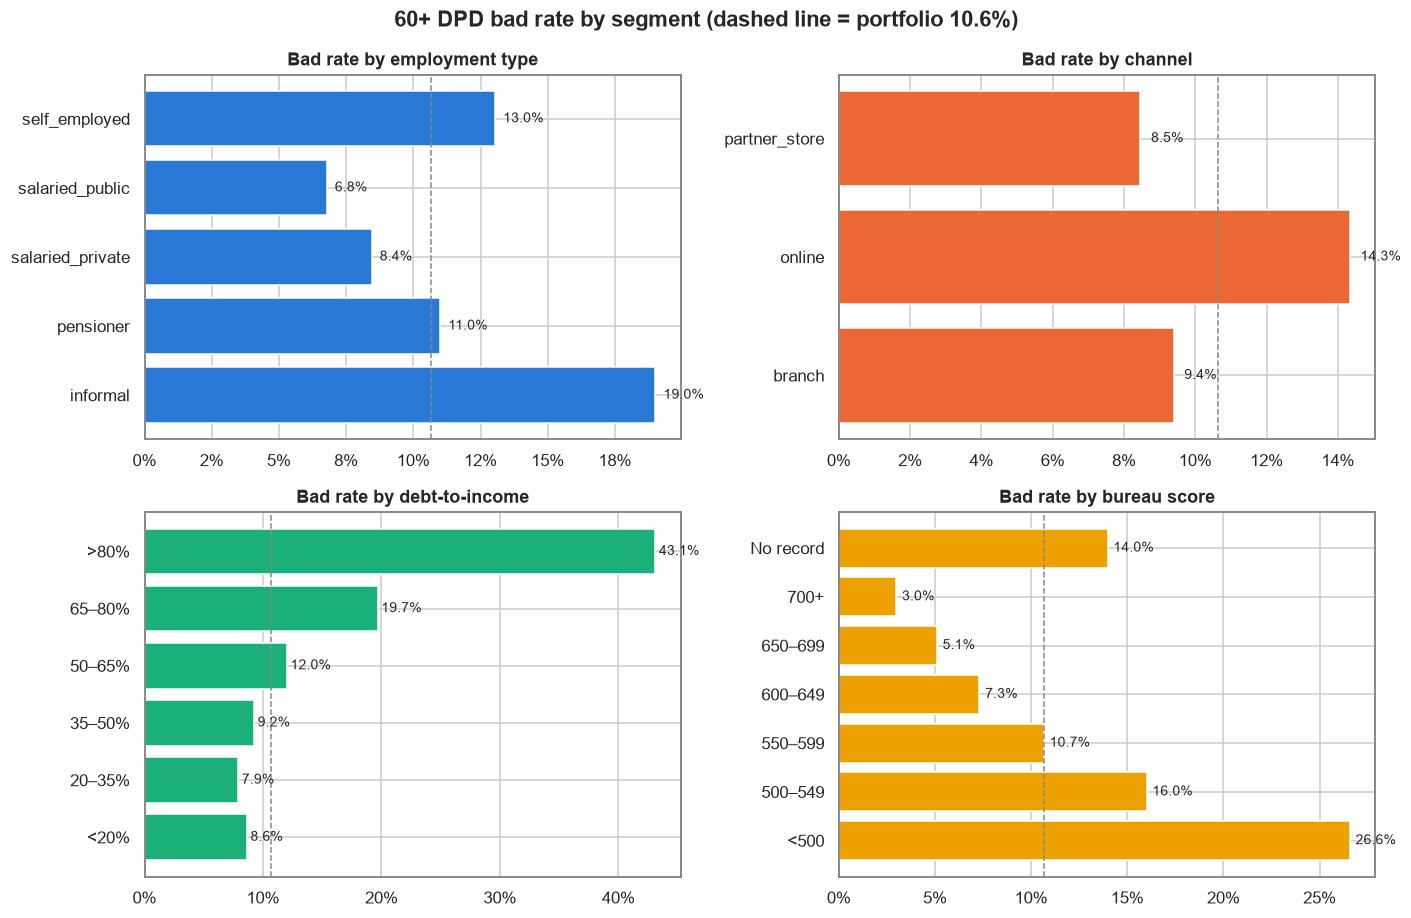

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8.5))
avg = df[T].mean()
def bar(a, s, title, color):
    s = s.sort_values() if s.index.dtype == object else s
    a.barh([str(i) for i in s.index], s.values, color=color); a.axvline(avg, color=GREY, ls="--", lw=1)
    a.xaxis.set_major_formatter(PercentFormatter(1, 0)); a.set_title(title)
    for y, v in enumerate(s.values): a.text(v + 0.003, y, f"{v:.1%}", va="center", fontsize=9)
bar(ax[0, 0], df.groupby("employment_type")[T].mean(), "Bad rate by employment type", BLUE)
bar(ax[0, 1], df.groupby("channel")[T].mean(), "Bad rate by channel", ORANGE)
dti_b = pd.cut(df.debt_to_income, [0, .2, .35, .5, .65, .8, 9], labels=["<20%", "20–35%", "35–50%", "50–65%", "65–80%", ">80%"])
bar(ax[1, 0], df.groupby(dti_b, observed=True)[T].mean(), "Bad rate by debt-to-income", AQUA)
bur_b = pd.cut(df.bureau_score, [0, 500, 550, 600, 650, 700, 900], labels=["<500", "500–549", "550–599", "600–649", "650–699", "700+"]).cat.add_categories("No record").fillna("No record")
bar(ax[1, 1], df.groupby(bur_b, observed=True)[T].mean(), "Bad rate by bureau score", YELLOW)
fig.suptitle(f"60+ DPD bad rate by segment (dashed line = portfolio {avg:.1%})", fontweight="bold")
plt.tight_layout(); plt.savefig("images/eda_bad_rates.png", bbox_inches="tight"); plt.show()

The bureau score separates risk strongly: below 500 about one loan in four goes bad, above 700 about one in fifty. Thin-file applicants (no bureau record) have a bad rate of ≈ 14%, above the average. Debt-to-income is almost flat up to about 50% and then rises steeply, so the current 80% rule is too loose. Informal workers and the online channel are the weakest segments.

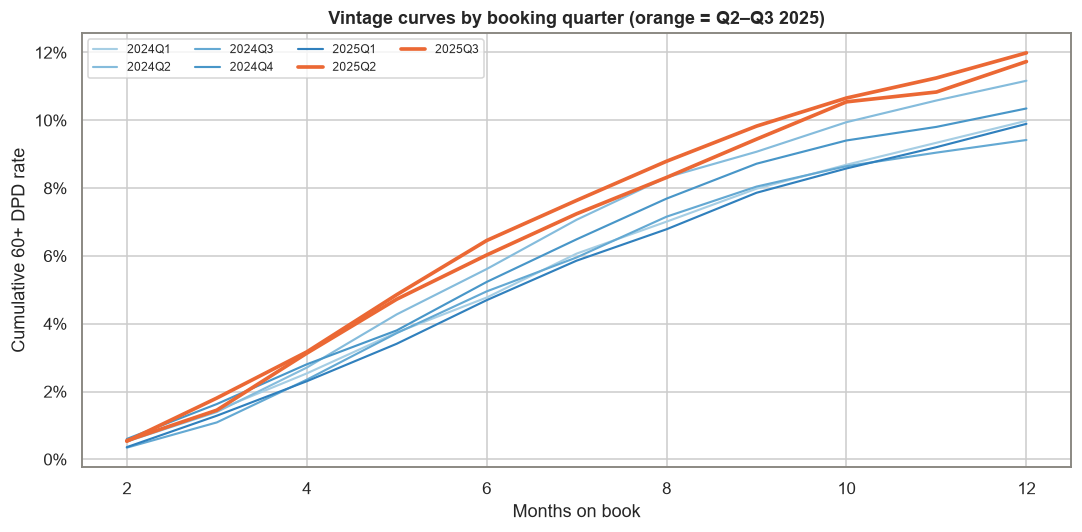

months_to_default,3.000000,6.000000,12.000000
quarter,,,
2024Q1,1.44%,4.77%,9.99%
2024Q2,1.40%,5.61%,11.17%
2024Q3,1.09%,4.95%,9.42%
2024Q4,1.63%,5.23%,10.35%
2025Q1,1.29%,4.69%,9.90%
2025Q2,1.45%,6.03%,11.73%
2025Q3,1.81%,6.45%,11.99%


In [6]:
bads = df[df[T] == 1]
cum = (bads.groupby(["quarter", "months_to_default"]).size().unstack(fill_value=0).cumsum(axis=1)
       .div(df.groupby("quarter").size(), axis=0))
fig, ax = plt.subplots(figsize=(10, 5))
cmap = plt.get_cmap("Blues")
for i, (q, r) in enumerate(cum.iterrows()):
    late = q >= "2025Q2"
    ax.plot(r.index, r.values, color=ORANGE if late else cmap(0.35 + 0.6 * i / len(cum)), lw=2.4 if late else 1.4, label=q)
ax.yaxis.set_major_formatter(PercentFormatter(1, 0)); ax.set_xlabel("Months on book"); ax.set_ylabel("Cumulative 60+ DPD rate")
ax.set_title("Vintage curves by booking quarter (orange = Q2–Q3 2025)"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig("images/vintage_curves.png", bbox_inches="tight"); plt.show()
cum[[3, 6, 12]].style.format("{:.2%}")

Defaults peak in months 4–7 on book; by month 6 about half of the 12-month bads are already visible, so a **6-month bad rate is a good early warning**. The two 2025 Q2–Q3 vintages run above every earlier vintage. The market got tougher, which the out-of-time test below has to cope with.

## 4. WoE binning and Information Value

In [7]:
FEATS = sc.NUMERIC + sc.CATEGORICAL
dev = df[df.application_date < "2025-04-01"].copy()
oot = df[df.application_date >= "2025-04-01"].copy()
train, test = train_test_split(dev, test_size=0.3, random_state=42, stratify=dev[T])
print(f"train {len(train):,} | test {len(test):,} | out-of-time {len(oot):,}")
binner = sc.WoEBinner(max_bins=6).fit(train[FEATS], train[T])
iv = binner.iv()
strength = pd.cut(iv, [-1, .02, .1, .3, 9], labels=["unpredictive", "weak", "medium", "strong"])
pd.DataFrame({"IV": iv, "strength": strength})

train 12,019 | test 5,151 | out-of-time 6,830


,IV,strength
bureau_score,0.429,strong
debt_to_income,0.222,medium
employment_type,0.167,medium
delinquencies_12m,0.134,medium
monthly_income_azn,0.098,weak
existing_loans,0.083,weak
channel,0.077,weak
salary_card_client,0.075,weak
employment_years,0.067,weak
age,0.062,weak


In [8]:
cand = iv[iv >= 0.02].index.tolist()
W = binner.transform(train[cand])
corr = W.corr()
drop = set()
for i, a in enumerate(cand):
    for b in cand[i + 1:]:
        if a not in drop and b not in drop and abs(corr.loc[a, b]) > 0.6:
            drop.add(b)                       # cand is sorted by IV, so b is the weaker one
print("Dropped for IV < 0.02:", iv[iv < 0.02].index.tolist())
print("Dropped for |WoE correlation| > 0.6:", sorted(drop))
print("Max |correlation| among remaining:", round((corr.loc[[c for c in cand if c not in drop], [c for c in cand if c not in drop]].abs()
      .where(~np.eye(len(cand) - len(drop), dtype=bool))).max().max(), 2))

Dropped for IV < 0.02: ['term_months', 'region']
Dropped for |WoE correlation| > 0.6: []
Max |correlation| among remaining: 0.57


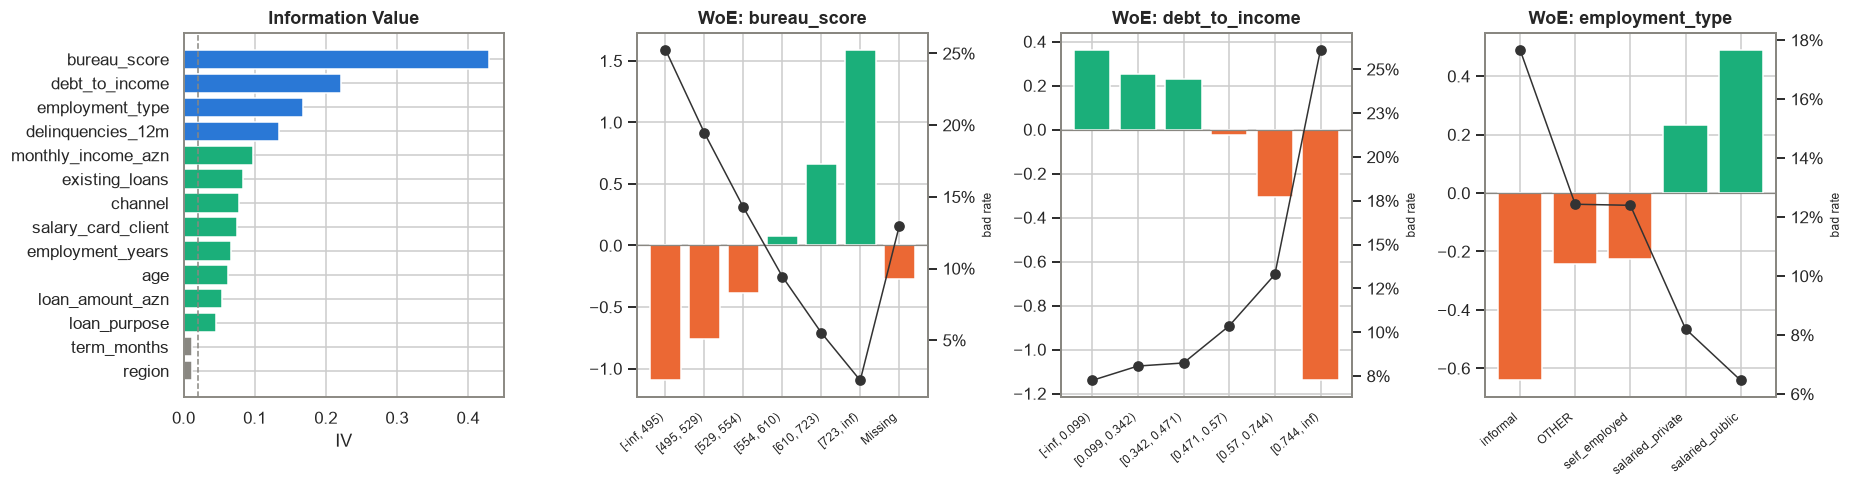

In [9]:
show = ["bureau_score", "debt_to_income", "employment_type"]
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]})
ax[0].barh(iv.index[::-1], iv.values[::-1], color=[BLUE if v >= .1 else (AQUA if v >= .02 else GREY) for v in iv.values[::-1]])
ax[0].axvline(0.02, color=GREY, ls="--", lw=1); ax[0].set_title("Information Value"); ax[0].set_xlabel("IV")
for a, f in zip(ax[1:], show):
    t = binner.tables[f]
    a.bar(range(len(t)), t.woe, color=[AQUA if w > 0 else ORANGE for w in t.woe])
    a.set_xticks(range(len(t))); a.set_xticklabels(t.index, rotation=40, ha="right", fontsize=8)
    a.set_title(f"WoE: {f}"); a.axhline(0, color=GREY, lw=0.8)
    a2 = a.twinx(); a2.plot(range(len(t)), t.bad_rate, "o-", color="#333", lw=1); a2.yaxis.set_major_formatter(PercentFormatter(1, 0))
    a2.grid(False); a2.set_ylabel("bad rate", fontsize=8)
plt.tight_layout(); plt.savefig("images/iv_woe.png", bbox_inches="tight"); plt.show()

The monotonic binning gives clean, explainable steps: each extra bureau-score band lowers the bad rate, and the WoE (log of good/bad distribution) moves in the same order. The bureau score is a **strong** predictor (IV ≈ 0.43). Debt-to-income and employment type are medium. Term and region add almost nothing on their own and are left out.

## 5. Logistic regression and validation

In [10]:
features = [c for c in cand if c not in drop]
model = LogisticRegression(C=1e3, max_iter=5000).fit(binner.transform(train[features]), train[T])
coef = pd.Series(model.coef_[0], index=features)
assert (coef < 0).all(), "every WoE coefficient should be negative (higher WoE = safer)"
def score(d):
    lg = model.intercept_[0] + binner.transform(d[features]) @ coef.values
    return sc.score_from_logit(lg), 1 / (1 + np.exp(-lg))
for d in (train, test, oot, recent):
    d["score"], d["pd"] = score(d)
rows = {}
for name, d in [("Train", train), ("Test (random 30%)", test), ("Out-of-time Apr–Sep 2025", oot)]:
    ks, _ = sc.ks_stat(d[T], d.score)
    rows[name] = {"n": len(d), "bad rate": d[T].mean(), "mean PD": d.pd.mean(),
                  "Gini": 2 * roc_auc_score(d[T], -d.score) - 1, "KS": ks}
bur_fill = oot.bureau_score.fillna(train.bureau_score.quantile(0.3))
rows["Benchmark: bureau score only (OOT)"] = {"n": len(oot), "bad rate": oot[T].mean(), "mean PD": np.nan,
    "Gini": 2 * roc_auc_score(oot[T], -bur_fill) - 1, "KS": sc.ks_stat(oot[T], bur_fill)[0]}
perf = pd.DataFrame(rows).T
display(coef.to_frame("coef").T)
perf

,bureau_score,debt_to_income,employment_type,delinquencies_12m,monthly_income_azn,existing_loans,channel,salary_card_client,employment_years,age,loan_amount_azn,loan_purpose
coef,-0.935,-0.752,-0.849,-0.684,-0.250,-0.310,-0.671,-0.466,-0.542,-0.491,-0.581,-0.447


,n,bad rate,mean PD,Gini,KS
Train,"12,019.000",0.102,0.102,0.535,0.407
Test (random 30%),"5,151.000",0.102,0.101,0.522,0.391
Out-of-time Apr–Sep 2025,"6,830.000",0.119,0.103,0.531,0.396
Benchmark: bureau score only (OOT),"6,830.000",0.119,NaN,0.380,0.280


In [11]:
thin = oot.bureau_score.isna()
print(f"OOT Gini, thin-file applicants only: {2 * roc_auc_score(oot.loc[thin, T], -oot.loc[thin, 'score']) - 1:.3f} (n={thin.sum():,}) — the bureau score cannot rank these at all")
# calibration drift: observed vs predicted log-odds on OOT
shift = np.log(oot[T].mean() / (1 - oot[T].mean())) - np.log(oot.pd.mean() / (1 - oot.pd.mean()))
print(f"OOT intercept shift needed for calibration: {shift:+.3f} log-odds ≈ {-shift * 20 / np.log(2):+.1f} points")

OOT Gini, thin-file applicants only: 0.223 (n=880) — the bureau score cannot rank these at all
OOT intercept shift needed for calibration: +0.159 log-odds ≈ -4.6 points


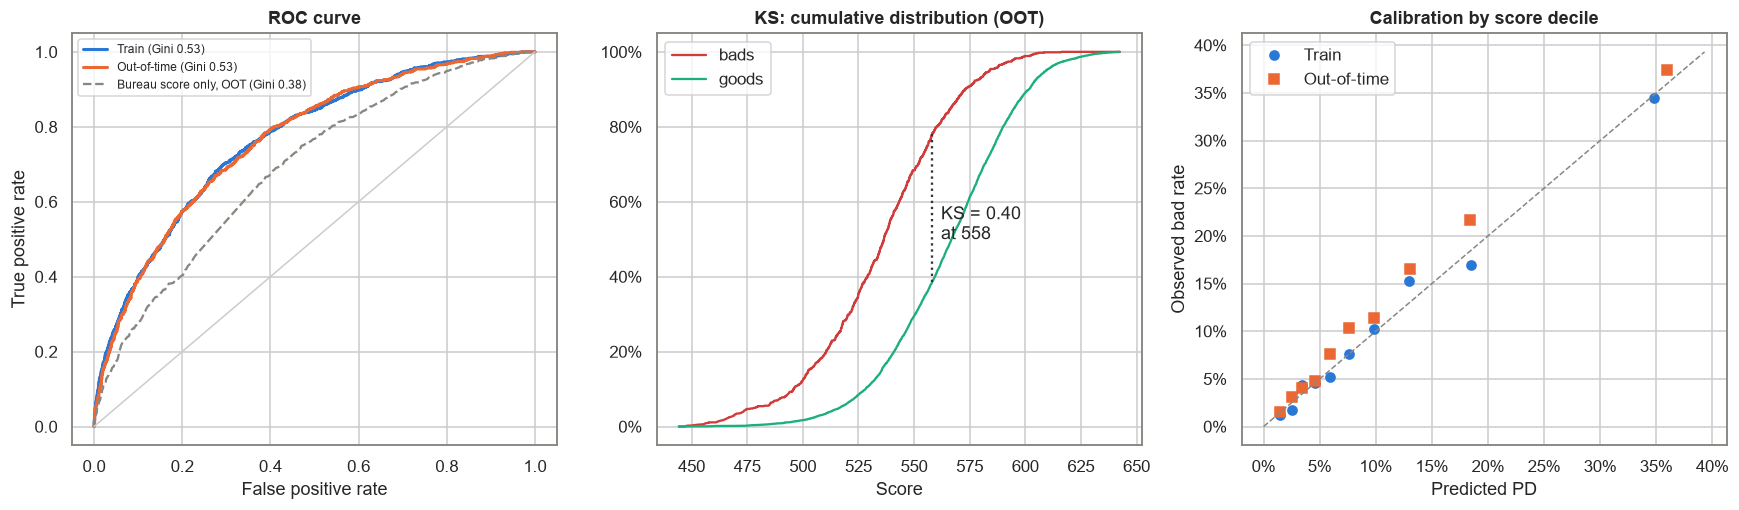

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for d, name, col in [(train, "Train", BLUE), (oot, "Out-of-time", ORANGE)]:
    fpr, tpr, _ = roc_curve(d[T], -d.score); ax[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (Gini {2 * roc_auc_score(d[T], -d.score) - 1:.2f})")
fpr, tpr, _ = roc_curve(oot[T], -bur_fill); ax[0].plot(fpr, tpr, color=GREY, ls="--", label=f"Bureau score only, OOT (Gini {perf.iloc[3].Gini:.2f})")
ax[0].plot([0, 1], [0, 1], color="#ccc", lw=1); ax[0].set_title("ROC curve"); ax[0].legend(fontsize=8); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
s = np.sort(oot.score.unique())
cb = [(oot.loc[oot[T] == 1, "score"] <= v).mean() for v in s]; cg = [(oot.loc[oot[T] == 0, "score"] <= v).mean() for v in s]
ks, ks_at = sc.ks_stat(oot[T], oot.score)
ax[1].plot(s, cb, color=RED, label="bads"); ax[1].plot(s, cg, color=AQUA, label="goods")
ax[1].vlines(ks_at, np.interp(ks_at, s, cg), np.interp(ks_at, s, cb), color="#333", ls=":"); ax[1].text(ks_at + 4, 0.5, f"KS = {ks:.2f}\nat {ks_at:.0f}")
ax[1].set_title("KS: cumulative distribution (OOT)"); ax[1].set_xlabel("Score"); ax[1].legend(); ax[1].yaxis.set_major_formatter(PercentFormatter(1, 0))
edges = np.quantile(train.score, np.linspace(0, 1, 11)); edges[0], edges[-1] = -np.inf, np.inf
cal = []
for d, name in [(train, "Train"), (oot, "Out-of-time")]:
    g = d.groupby(pd.cut(d.score, edges, labels=False), observed=True).agg(pred=("pd", "mean"), obs=(T, "mean"))
    g["sample"] = name; cal.append(g)
cal = pd.concat(cal)
for name, col, m in [("Train", BLUE, "o"), ("Out-of-time", ORANGE, "s")]:
    g = cal[cal["sample"] == name]; ax[2].plot(g.pred, g.obs, m, color=col, label=name)
mx = cal[["pred", "obs"]].max().max() * 1.05
ax[2].plot([0, mx], [0, mx], color=GREY, ls="--", lw=1); ax[2].set_title("Calibration by score decile")
ax[2].set_xlabel("Predicted PD"); ax[2].set_ylabel("Observed bad rate"); ax[2].legend()
ax[2].xaxis.set_major_formatter(PercentFormatter(1, 0)); ax[2].yaxis.set_major_formatter(PercentFormatter(1, 0))
plt.tight_layout(); plt.savefig("images/model_performance.png", bbox_inches="tight"); plt.show()

Ranking holds up: the Gini is almost the same on train, random test and out-of-time data, and well above the bureau score alone. The scorecard also ranks the thin-file customers the bureau cannot see. **Calibration** is the weak spot: in the tougher 2025 Q2–Q3 market the observed bad rate is above the predicted PD in most deciles. The order of risk is right but the level is too low, so PDs used for pricing or provisioning need an intercept adjustment (≈ 0.16 log-odds).

## 6. The scorecard

In [13]:
pts = sc.points_table(binner, features, coef.values, model.intercept_[0])
pts["points"] = pts.points.round().astype(int)
print(f"Score range: {pts.groupby('feature').points.min().sum()} – {pts.groupby('feature').points.max().sum()}   "
      f"(600 = odds 50:1 good:bad, +20 points doubles the odds)")
spread = pts.groupby("feature").points.agg(lambda p: p.max() - p.min()).sort_values(ascending=False)
print("Points spread per feature:", spread.to_dict())
pts.set_index(["feature", "bin"]).loc[spread.index[:5]].style.format({"bad_rate": "{:.1%}", "woe": "{:+.2f}"})

Score range: 416 – 653   (600 = odds 50:1 good:bad, +20 points doubles the odds)
Points spread per feature: {'bureau_score': 73, 'debt_to_income': 33, 'employment_type': 28, 'delinquencies_12m': 17, 'loan_amount_azn': 16, 'employment_years': 14, 'channel': 13, 'age': 11, 'existing_loans': 9, 'monthly_income_azn': 8, 'salary_card_client': 8, 'loan_purpose': 7}


In [14]:
band = pd.cut(oot.score, [-np.inf, 520, 540, 560, 580, 600, 620, np.inf], labels=["<520", "520–539", "540–559", "560–579", "580–599", "600–619", "620+"])
oot.groupby(band, observed=True).agg(loans=(T, "size"), share=(T, lambda s: len(s) / len(oot)), bad_rate=(T, "mean"),
                                     mean_pd=("pd", "mean")).style.format({"share": "{:.1%}", "bad_rate": "{:.2%}", "mean_pd": "{:.2%}"})

,loans,share,bad_rate,mean_pd
score,,,,
<520,611,8.9%,38.79%,37.63%
520–539,990,14.5%,21.72%,17.93%
540–559,1506,22.0%,13.01%,10.22%
560–579,1730,25.3%,6.18%,5.44%
580–599,1327,19.4%,3.47%,2.88%
600–619,540,7.9%,1.67%,1.55%
620+,126,1.8%,0.00%,0.76%


## 7. Cut-off strategy (out-of-time sample)

In [15]:
oot["profit"] = sc.loan_profit(oot.loan_amount_azn, oot.term_months, oot[T])
cuts = np.arange(500, 641, 2)
cs = pd.DataFrame([{"cutoff": c, "approval": (oot.score >= c).mean(), "bad_rate": oot.loc[oot.score >= c, T].mean(),
                    "profit": oot.loc[oot.score >= c, "profit"].sum()} for c in cuts])
best = cs.loc[cs.profit.idxmax()]
base_profit = oot.profit.sum()
print(f"Current policy (approve all booked): profit AZN {base_profit:,.0f}, bad rate {oot[T].mean():.2%}")
print(f"Profit-maximising cut-off {best.cutoff:.0f}: approve {best.approval:.1%}, bad rate {best.bad_rate:.2%}, "
      f"profit AZN {best.profit:,.0f} ({best.profit - base_profit:+,.0f}, {best.profit / base_profit - 1:+.1%})")
dec = oot[oot.score < best.cutoff]
print(f"Declined at that cut-off: {len(dec):,} loans, bad rate {dec[T].mean():.1%}, together they would have lost AZN {-dec.profit.sum():,.0f}")
CUT = int(best.cutoff)

Current policy (approve all booked): profit AZN 996,684, bad rate 11.86%
Profit-maximising cut-off 540: approve 76.6%, bad rate 6.85%, profit AZN 1,275,144 (+278,459, +27.9%)
Declined at that cut-off: 1,601 loans, bad rate 28.2%, together they would have lost AZN 278,459


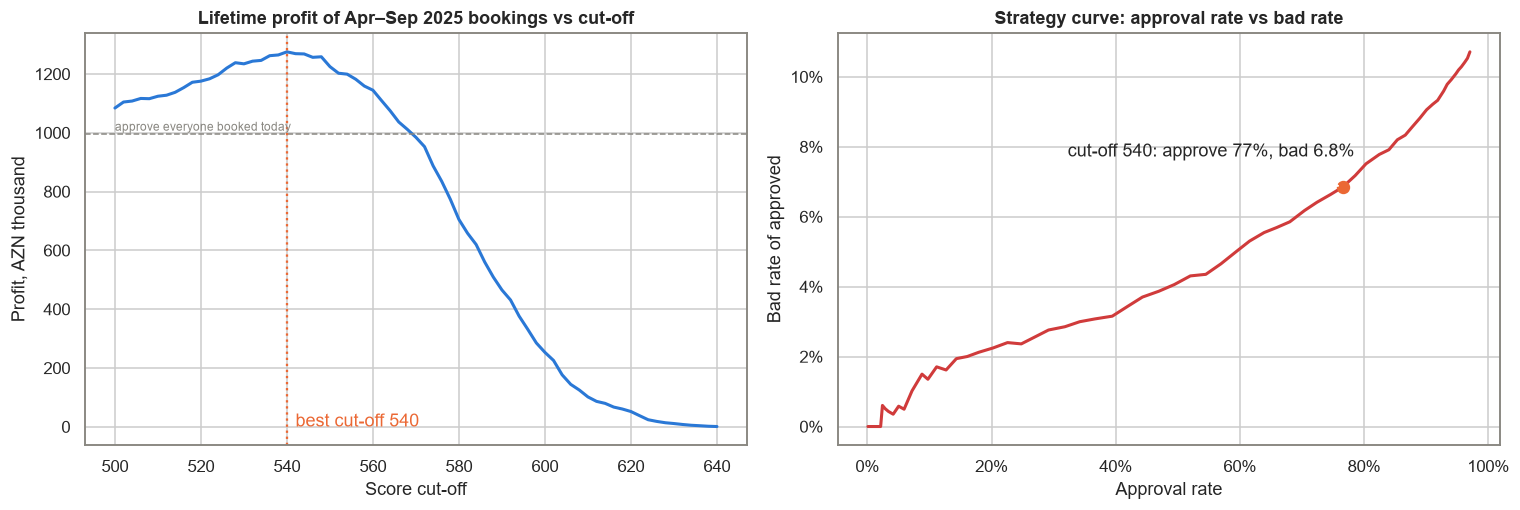

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(cs.cutoff, cs.profit / 1e3, color=BLUE, lw=2); ax[0].axhline(base_profit / 1e3, color=GREY, ls="--", lw=1)
ax[0].axvline(CUT, color=ORANGE, ls=":"); ax[0].text(CUT + 2, cs.profit.min() / 1e3, f"best cut-off {CUT}", color=ORANGE)
ax[0].text(cs.cutoff.min(), base_profit / 1e3 * 1.01, "approve everyone booked today", color=GREY, fontsize=8)
ax[0].set_title("Lifetime profit of Apr–Sep 2025 bookings vs cut-off"); ax[0].set_xlabel("Score cut-off"); ax[0].set_ylabel("Profit, AZN thousand")
ax[1].plot(cs.approval, cs.bad_rate, color=RED, lw=2)
ax[1].scatter([best.approval], [best.bad_rate], color=ORANGE, zorder=3, s=60); ax[1].annotate(f"cut-off {CUT}: approve {best.approval:.0%}, bad {best.bad_rate:.1%}",
             (best.approval, best.bad_rate), xytext=(-180, 20), textcoords="offset points", arrowprops={"arrowstyle": "->"})
ax[1].xaxis.set_major_formatter(PercentFormatter(1, 0)); ax[1].yaxis.set_major_formatter(PercentFormatter(1, 0))
ax[1].set_title("Strategy curve: approval rate vs bad rate"); ax[1].set_xlabel("Approval rate"); ax[1].set_ylabel("Bad rate of approved")
plt.tight_layout(); plt.savefig("images/cutoff_strategy.png", bbox_inches="tight"); plt.show()

In [17]:
seg = oot.assign(declined=oot.score < CUT)
pd.concat({c: seg.groupby(c).declined.mean() for c in ["channel", "employment_type"]}).to_frame("decline rate at cut-off").style.format("{:.1%}")

Under these unit economics a good loan earns about AZN 0.07 per AZN lent per year, and a bad one loses about AZN 0.56. So one bad costs as much as several years of interest from a good loan. Declining the lowest-scoring tail removes loans that lose money on average. The profit curve is fairly flat around the optimum, so the business can pick a cut-off a few points either side to hit a volume target without giving up much.

## 8. Stability: are today's applicants like the development sample?

In [18]:
edges = np.quantile(train.score, np.linspace(0, 1, 11)); edges[0], edges[-1] = -np.inf, np.inf
p_score, e, a = sc.psi(train.score, recent.score, edges)
p_oot, _, _ = sc.psi(train.score, oot.score, edges)
print(f"Score PSI  train → OOT 2025: {p_oot:.3f} | train → applications Apr–Sep 2026: {p_score:.3f}  (<0.10 stable, 0.10–0.25 monitor, >0.25 act)")
TB, RB = binner.bins(train[features]), binner.bins(recent[features])
csi = pd.Series({f: sc.psi_categorical(TB[f], RB[f]) for f in features}).sort_values(ascending=False)
print(f"Mean predicted PD: train {train.pd.mean():.2%} → 2026 applications {recent.pd.mean():.2%}; "
      f"share below cut-off {CUT}: {(train.score < CUT).mean():.1%} → {(recent.score < CUT).mean():.1%}")
csi.to_frame("CSI").round(3).T

Score PSI  train → OOT 2025: 0.002 | train → applications Apr–Sep 2026: 0.021  (<0.10 stable, 0.10–0.25 monitor, >0.25 act)
Mean predicted PD: train 10.16% → 2026 applications 11.24%; share below cut-off 540: 23.0% → 27.1%


,channel,age,employment_years,monthly_income_azn,bureau_score,employment_type,loan_purpose,loan_amount_azn,debt_to_income,salary_card_client,delinquencies_12m,existing_loans
CSI,0.114,0.083,0.042,0.028,0.027,0.008,0.005,0.003,0.001,0.001,0.001,0.000


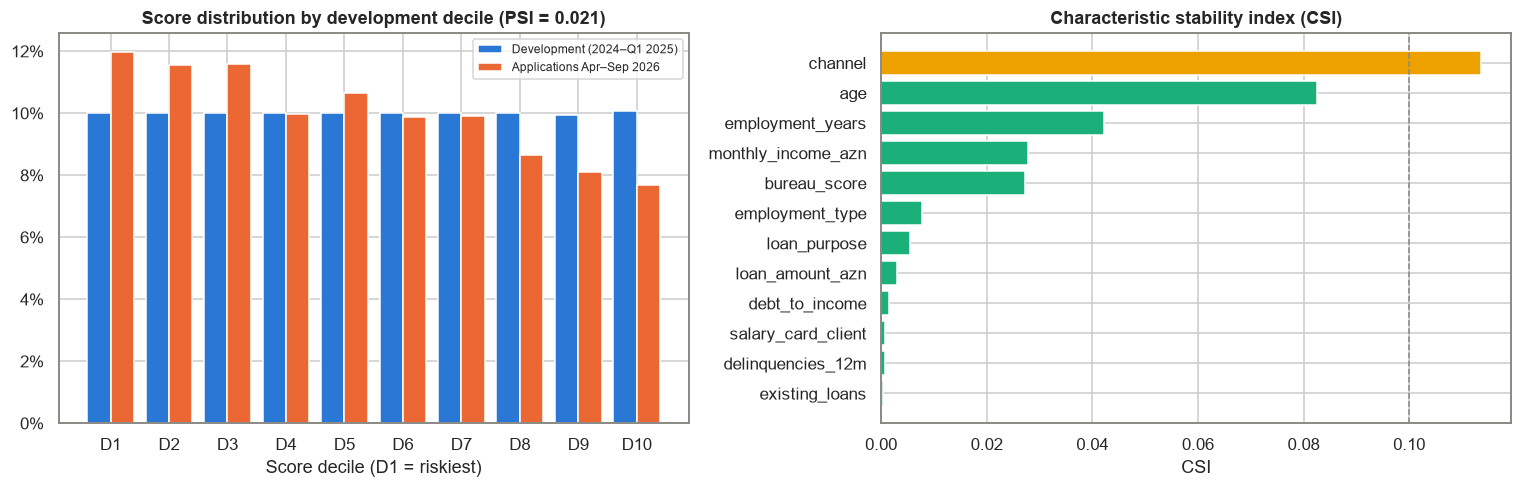

,development,2026 applications
channel,,
branch,45.3%,32.7%
online,29.4%,45.2%
partner_store,25.3%,22.1%


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.arange(10); w = 0.4
ax[0].bar(x - w / 2, e, w, color=BLUE, label="Development (2024–Q1 2025)"); ax[0].bar(x + w / 2, a, w, color=ORANGE, label="Applications Apr–Sep 2026")
ax[0].set_xticks(x); ax[0].set_xticklabels([f"D{i + 1}" for i in x]); ax[0].yaxis.set_major_formatter(PercentFormatter(1, 0))
ax[0].set_title(f"Score distribution by development decile (PSI = {p_score:.3f})"); ax[0].set_xlabel("Score decile (D1 = riskiest)"); ax[0].legend(fontsize=8)
ax[1].barh(csi.index[::-1], csi.values[::-1], color=[RED if v > .25 else (YELLOW if v > .1 else AQUA) for v in csi.values[::-1]])
ax[1].axvline(0.1, color=GREY, ls="--", lw=1); ax[1].set_title("Characteristic stability index (CSI)"); ax[1].set_xlabel("CSI")
plt.tight_layout(); plt.savefig("images/psi_stability.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"development": train.channel.value_counts(normalize=True), "2026 applications": recent.channel.value_counts(normalize=True)}).style.format("{:.1%}")

The overall score distribution is still **stable** (PSI well under 0.10), but the mix underneath is moving: the **channel** CSI is already in the "monitor" zone because online grew from 30% to 45% of applications, and applicants are younger. Mean predicted PD goes up by about one percentage point and more applicants fall below the cut-off. Nothing is broken yet, but this is how a scorecard drifts. Set the approval budget from the 2026 mix, not the 2024 one, and track PSI/CSI every month.

## 9. Findings & recommendations

In [20]:
summary = pd.DataFrame([
 ["Ranking power", f"OOT Gini {perf.iloc[2].Gini:.2f} / KS {perf.iloc[2].KS:.2f} vs bureau score alone Gini {perf.iloc[3].Gini:.2f}", "Deploy the scorecard as the primary decision tool; keep the bureau score as one input, not the policy"],
 ["Cut-off", f"Cut-off {CUT}: approve {best.approval:.0%}, bad rate {oot[T].mean():.1%} → {best.bad_rate:.1%}, profit {best.profit / base_profit - 1:+.0%}", f"Introduce a score cut-off around {CUT}, with a manual-review band of ±10 points"],
 ["Affordability", "Bad rate flat to DTI 50%, then 13% at 57–74% and 26% above 74%", "Tighten the instalment rule from 80% to ~60% of income, or price the extra risk"],
 ["Thin file", f"{df.bureau_score.isna().mean():.0%} of loans, bad rate {df.loc[df.bureau_score.isna(), T].mean():.1%}; scorecard Gini on them {2 * roc_auc_score(oot.loc[thin, T], -oot.loc[thin, 'score']) - 1:.2f}", "Keep lending to thin files using the scorecard; add salary-card / payroll data to grow this segment safely"],
 ["Calibration", f"OOT observed bad rate {oot[T].mean():.1%} vs predicted {oot.pd.mean():.1%} (shift {shift:+.2f} log-odds)", "Recalibrate the intercept every quarter before using PD for pricing or IFRS 9 provisions"],
 ["Population drift", f"2026 score PSI {p_score:.3f}; top CSI: {csi.index[0]} ({csi.iloc[0]:.2f}); mean PD {train.pd.mean():.1%} → {recent.pd.mean():.1%}", "Monthly PSI/CSI dashboard; review the online channel's acquisition and fraud checks"],
 ["Early warning", f"Median default at month {df.months_to_default.median():.0f}; ≈ half of 12-month bads visible by month 6", "Track 3/6-month vintage bad rates to catch a bad vintage two quarters earlier"],
], columns=["Area", "Evidence", "Recommendation"])
summary.style.hide(axis="index")

Area,Evidence,Recommendation
Ranking power,OOT Gini 0.53 / KS 0.40 vs bureau score alone Gini 0.38,"Deploy the scorecard as the primary decision tool; keep the bureau score as one input, not the policy"
Cut-off,"Cut-off 540: approve 77%, bad rate 11.9% → 6.8%, profit +28%","Introduce a score cut-off around 540, with a manual-review band of ±10 points"
Affordability,"Bad rate flat to DTI 50%, then 13% at 57–74% and 26% above 74%","Tighten the instalment rule from 80% to ~60% of income, or price the extra risk"
Thin file,"14% of loans, bad rate 14.0%; scorecard Gini on them 0.22",Keep lending to thin files using the scorecard; add salary-card / payroll data to grow this segment safely
Calibration,OOT observed bad rate 11.9% vs predicted 10.3% (shift +0.16 log-odds),Recalibrate the intercept every quarter before using PD for pricing or IFRS 9 provisions
Population drift,2026 score PSI 0.021; top CSI: channel (0.11); mean PD 10.2% → 11.2%,Monthly PSI/CSI dashboard; review the online channel's acquisition and fraud checks
Early warning,Median default at month 6; ≈ half of 12-month bads visible by month 6,Track 3/6-month vintage bad rates to catch a bad vintage two quarters earlier


**Bottom line:** a 12-characteristic WoE scorecard ranks risk clearly better than the bureau score and keeps its ranking out of time. A score cut-off declines the lowest-scoring quarter of applicants (bad rate ≈ 28%, loss-making on average) and raises profit by more than a quarter. The PD level drifts with the market, so recalibrate it quarterly and watch PSI as the 2026 applicant mix moves online.

*Caveats: outcomes exist only for loans that were approved, so the model has not seen rejected applicants (no reject inference). Unit economics are simplified (flat net margin, EAD 80%, LGD 70%, no early repayment).*